<a href="https://colab.research.google.com/github/akinlayoadeniran/marketing-analytics-ml/blob/main/Akinlayo_Forecasting_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.datasets import co2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

#Exercise 1

In [4]:
data = co2.load_pandas().data.copy()
data = data.rename(columns={"co2": "co2_ppm"})
monthly = data["co2_ppm"].resample("MS").mean().interpolate()
monthly.head()

,co2_ppm
1958-03-01,316.100000
1958-04-01,317.200000
1958-05-01,317.433333
1958-06-01,316.529167
1958-07-01,315.625000


#Exercise 2

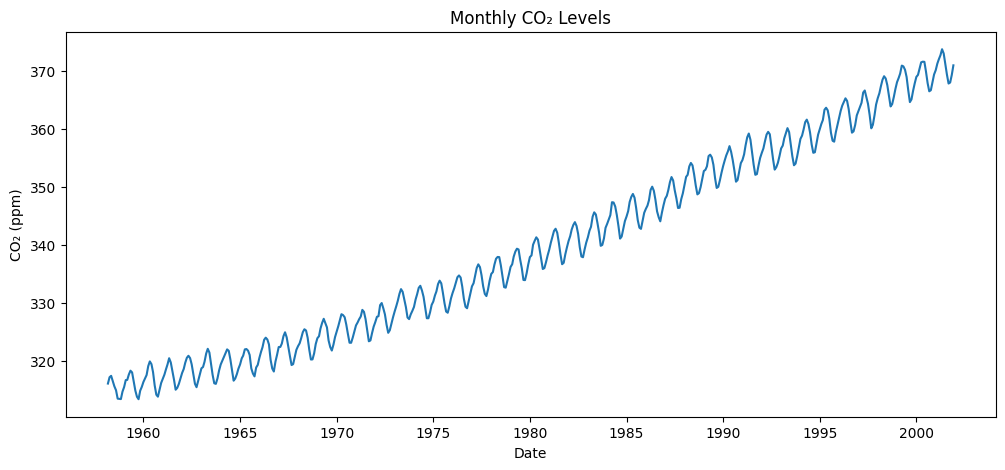

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(monthly)
plt.title("Monthly CO₂ Levels")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.show()

#Exercise 3

Train shape: (502, 3)
Test shape: (24, 3)


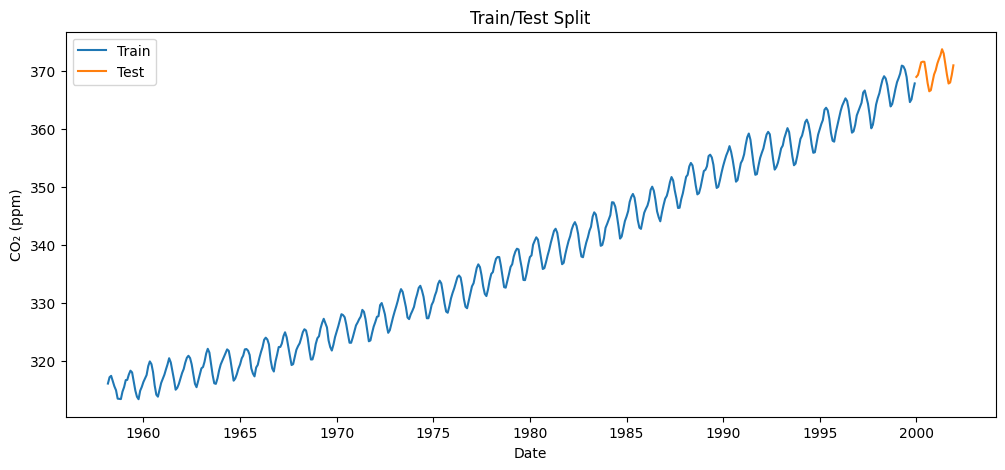

In [8]:
ts = monthly.to_frame(name="co2_ppm").reset_index().rename(columns={"index":"date"})
ts["time_index"] = np.arange(len(ts))
train = ts.iloc[:-24].copy()
test = ts.iloc[-24:].copy()
print("Train shape:" , train.shape)
print("Test shape:" , test.shape)
ts.head()

plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.title("Train/Test Split")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

Time series data has an order, and each value depends on the ones before it. If I shuffled the data, months from the test period would end up in the training set, so the model would be trained on the future and then asked to predict it. That is cheating, and the error would look much smaller than it really is. It also breaks the trend and the yearly pattern, because the months would no longer be in sequence. In my notebook I kept the order and used the last 24 months as the test set, so the model only learns from the past and is tested on data it has not seen, like a real forecast.

#Exercise 4

In [12]:
last_train_value = train["co2_ppm"].iloc[-1]
test["naive_forecast"] = last_train_value
test[["date","co2_ppm","naive_forecast"]].head()


,date,co2_ppm,naive_forecast
502,2000-01-01,369.020,367.9
503,2000-02-01,369.375,367.9
504,2000-03-01,370.400,367.9
505,2000-04-01,371.540,367.9
506,2000-05-01,371.650,367.9


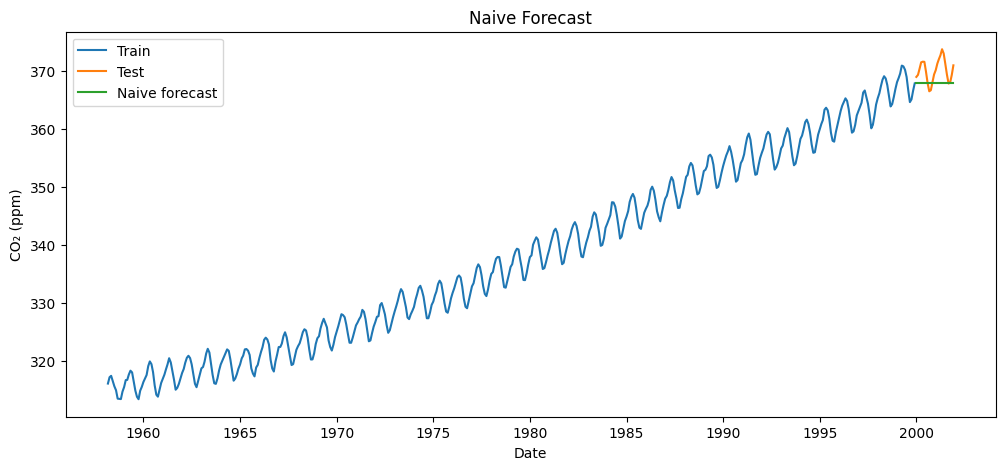

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.plot(test["date"], test["naive_forecast"], label="Naive forecast")
plt.title("Naive Forecast")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

The naive method is very simple and fast. It needs no model and no training, just the last observed value, so it is easy to explain and to build. It also gives a baseline: any more complicated method should beat the naive forecast, or it is not worth using.

#Exercise 5

In [17]:
window = 12
moving_avg_value = train["co2_ppm"].tail(window).mean()
test["moving_average_forecast"] = moving_avg_value
test[["date", "co2_ppm", "moving_average_forecast"]].head()

,date,co2_ppm,moving_average_forecast
502,2000-01-01,369.020,368.225
503,2000-02-01,369.375,368.225
504,2000-03-01,370.400,368.225
505,2000-04-01,371.540,368.225
506,2000-05-01,371.650,368.225


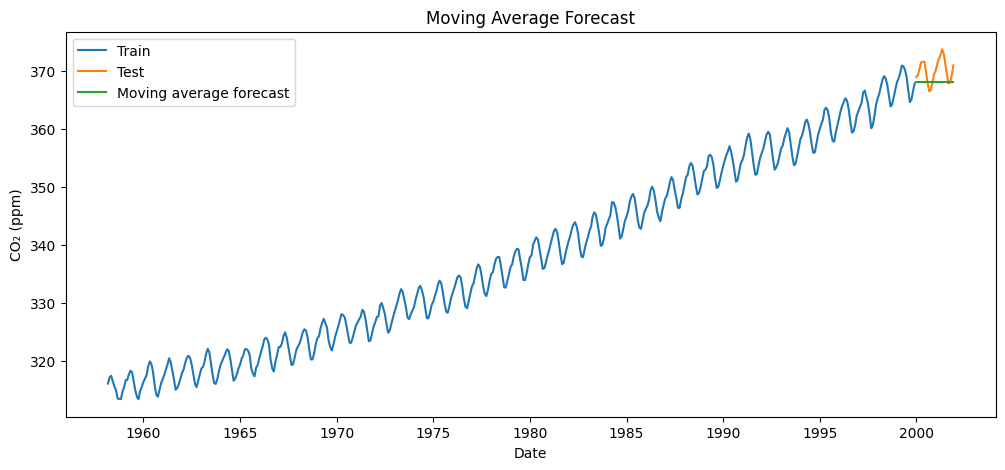

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.plot(test["date"], test["moving_average_forecast"], label="Moving average forecast")
plt.title("Moving Average Forecast")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

The naive forecast uses only the last observed value, so it depends on one single month, and that month could be a high or a low point in the yearly wave. The moving average uses the average of the last 12 months, which smooths out the seasonal ups and downs and gives a more stable value. Both produce a flat line, though, so neither can follow the upward trend or the seasonal pattern.

#Exercise 6

In [19]:
X_train = train[["time_index"]]
y_train = train["co2_ppm"]
X_test = test[["time_index"]]
y_test = test["co2_ppm"]

reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

test["regression_forecast"] = reg_model.predict(X_test)
test[["date", "co2_ppm", "regression_forecast"]].head()

,date,co2_ppm,regression_forecast
502,2000-01-01,369.020,365.730672
503,2000-02-01,369.375,365.840291
504,2000-03-01,370.400,365.949909
505,2000-04-01,371.540,366.059528
506,2000-05-01,371.650,366.169147


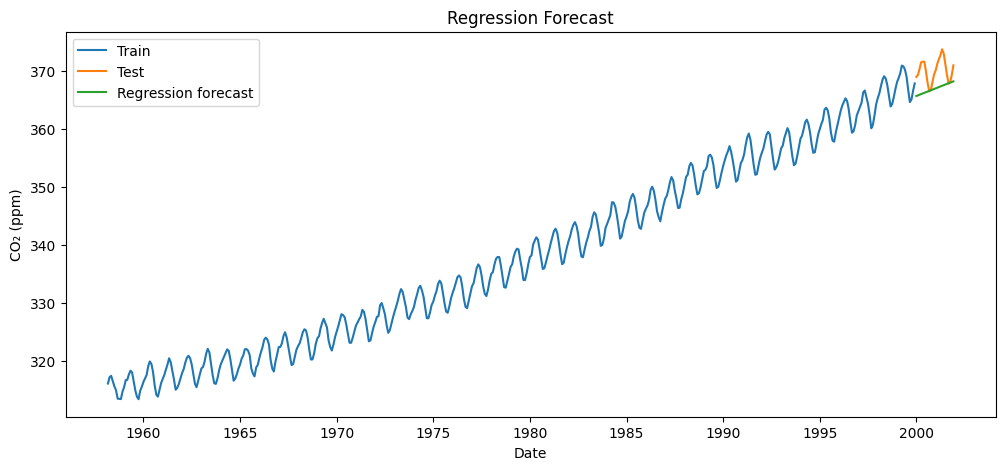

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.plot(test["date"], test["regression_forecast"], label="Regression forecast")
plt.title("Regression Forecast")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

Regression might work better because the series has a clear upward trend, and the regression line follows it, so its forecasts keep rising over time. The naive method repeats one value, so it stays flat while the real data keeps going up, and its error grows. In my results, however, the regression forecast sat below the real values, because a straight line does not capture how CO₂ rose faster in the later years. So regression follows the direction of the trend, but a simple straight line still has limits.

#Exercise 7

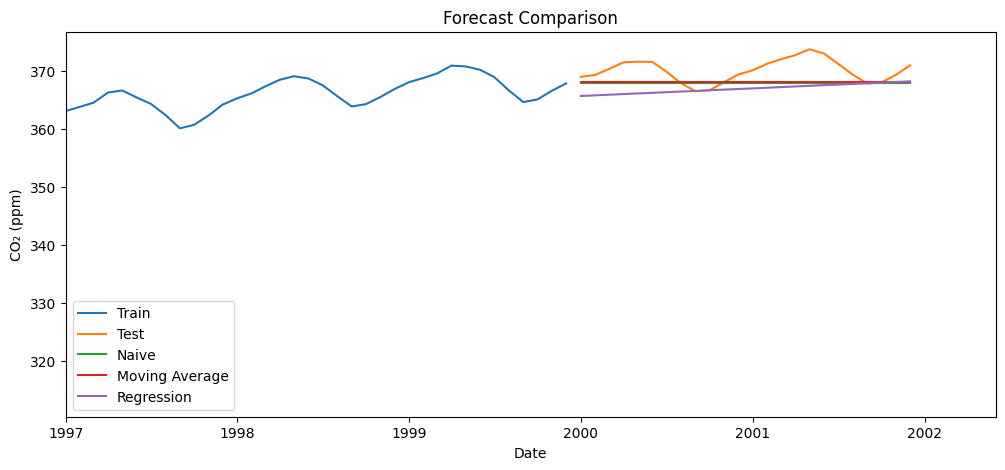

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.plot(test["date"], test["naive_forecast"], label="Naive")
plt.plot(test["date"], test["moving_average_forecast"], label="Moving Average")
plt.plot(test["date"], test["regression_forecast"], label="Regression")
plt.title("Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.xlim(pd.Timestamp("1997-01-01"), pd.Timestamp("2002-06-01"))
plt.show()

The naive and moving average forecasts look closest, because they are flat lines that run through the lower-middle part of the real data, and they stay within a few ppm of it. The regression forecast starts about 3 ppm too low, but it rises and gets closer by the end of the test period. None of the forecasts follows the yearly wave, and the real data goes above all of them during most of the first year. It is hard to be sure by eye, so I will check the MAE and RMSE values.

#Exercise 8

In [30]:
results = pd.DataFrame({
    "method": ["Naive", "Moving Average", "Regression"],
    "MAE": [
        mean_absolute_error(y_test, test["naive_forecast"]),
        mean_absolute_error(y_test, test["moving_average_forecast"]),
        mean_absolute_error(y_test, test["regression_forecast"])
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, test["naive_forecast"])),
        np.sqrt(mean_squared_error(y_test, test["moving_average_forecast"])),
        np.sqrt(mean_squared_error(y_test, test["regression_forecast"]))
    ]
})

results.sort_values("MAE")

,method,MAE,RMSE
1,Moving Average,2.222292,2.692715
0,Naive,2.420208,2.929135
2,Regression,3.125228,3.698257


The moving average performs best, with an MAE of about 2.22 ppm and an RMSE of about 2.69. The naive method is second (MAE 2.42), and the regression is the worst (MAE 3.13). MAE and RMSE give the same order. This surprised me, because the series has a clear upward trend and I expected regression to win. The straight line was fitted to 40 years of data, so it ran below the real values at the end, where CO₂ was rising faster. The moving average uses the most recent 12 months, so it starts close to the recent level,

#Exercise 9

In [31]:

ts["month"] = ts["date"].dt.month
month_dummies = pd.get_dummies(ts["month"], prefix="month", drop_first=True, dtype=float)
X_month = pd.concat([ts[["time_index"]], month_dummies], axis=1)
X_train_m = X_month.iloc[:-24]
X_test_m = X_month.iloc[-24:]
reg_month = LinearRegression()
reg_month.fit(X_train_m, y_train)
test["regression_month_forecast"] = reg_month.predict(X_test_m)
new_row = pd.DataFrame({
    "method": ["Regression + month"],
    "MAE": [mean_absolute_error(y_test, test["regression_month_forecast"])],
    "RMSE": [np.sqrt(mean_squared_error(y_test, test["regression_month_forecast"]))]
})
results_all = pd.concat([results, new_row], ignore_index=True)
results_all.sort_values("MAE")

,method,MAE,RMSE
1,Moving Average,2.222292,2.692715
0,Naive,2.420208,2.929135
3,Regression + month,3.062261,3.074568
2,Regression,3.125228,3.698257


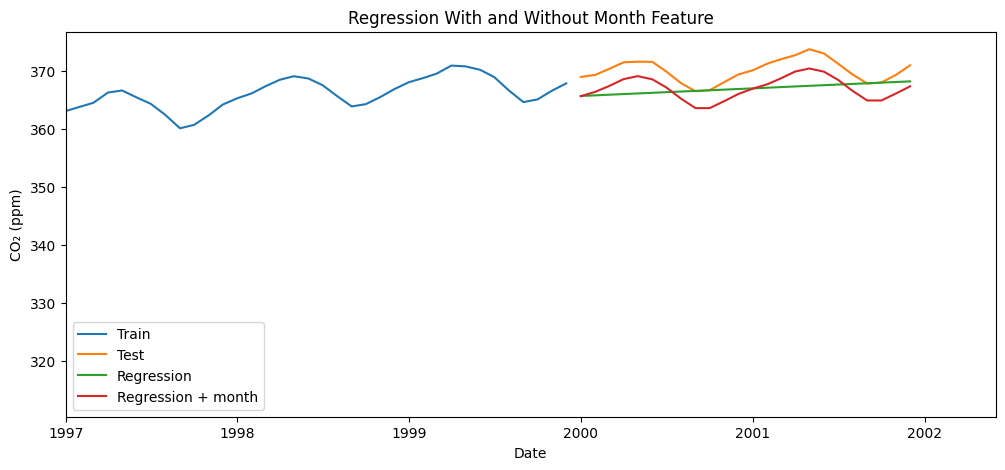

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["co2_ppm"], label="Train")
plt.plot(test["date"], test["co2_ppm"], label="Test")
plt.plot(test["date"], test["regression_forecast"], label="Regression")
plt.plot(test["date"], test["regression_month_forecast"], label="Regression + month")
plt.title("Regression With and Without Month Feature")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.xlim(pd.Timestamp("1997-01-01"), pd.Timestamp("2002-06-01"))
plt.show()

I added the month of the year as a feature using dummy columns and trained a new regression. The new forecast follows the yearly seasonal wave, which the straight-line regression could not do, and its RMSE improved from 3.70 to 3.07. The MAE improved only slightly (3.13 to 3.06), because the forecast is still about 3 ppm below the real data. This is because the straight-line trend is too low at the end of the series, where CO₂ was rising faster. The new model is still worse than the moving average (MAE 2.22) and the naive forecast (MAE 2.42). So the month feature solves the seasonality problem but not the trend problem.

#Reflection

1. What is the difference between naive, moving average, and regression forecasting?
The naive forecast takes the last observed value and repeats it for every future month. The moving average takes the average of the last 12 months and repeats that. Both give a flat line. Regression fits a straight line to the whole training period against time and extends it into the future, so it can rise.

2. Why is train/test split important in time series?
It lets me test the model on data it has never seen, like a real forecast. In time series the split must keep the order, with the past for training and the last months for testing. If the data were shuffled, the model would learn from the future and the error would look much smaller than it really is.

3. Which method worked best on this dataset?
The moving average worked best, with an MAE of 2.22 and an RMSE of 2.69. The naive method was second and the regression was last. I expected regression to win because of the upward trend, but the straight line was too low at the end of the data, because CO₂ rose faster in the later years. This is only a 24-month test, so the ranking could change with a different split.

4. Why might seasonality be difficult for simple linear regression?
A straight line only has one slope, so it can only go up or down, never up and down every year. It can follow the trend but can’t follow the repeating yearly wave. To capture seasonality I would need extra features, like the month of the year.